In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

C:\Users\rosha\.conda\envs\eds220-env\Lib\site-packages\nbformat\validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '9eced71a'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
C:\Users\rosha\.conda\envs\eds220-env\Lib\site-packages\nbformat\validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to 'ceaac520'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
C:\Users\rosha\.conda\envs\eds220-env\Lib\site-packages\nbformat\validator.py:434: DuplicateCellId: Non-unique cell id 'b134f8b7-4527-44b2-95f8-2e55880dd4f0' detected. Corrected to '4dd97a4b'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/roshananair/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [ ]:
# FINAL CODE

# Importing packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Setting black plot style
plt.style.use('dark_background')

# Read in spill data
fp = 'data/Spill_Incidents_20261102.csv'
spills = pd.read_csv(fp)

# Read in county shapefile
fp = 'data/tl_2026_us_county.shp'
counties = gpd.read_file(fp)

# Simplifying column names to snakecase
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

# Columns to change type
date_cols = ['spill_date', 'received_date', 'close_date']
str_float_cols = ['quantity', 'recovered']

# Coercing date cols to datetime and columns of string numbers to floats
spills[date_cols] = spills[date_cols].apply(pd.to_datetime, errors = 'coerce')
spills[str_float_cols] = spills[str_float_cols].apply(pd.to_numeric, errors = 'coerce')

# Creating df containing petroleum spills in 2023
petr_23 = spills[(spills['spill_date'].between('01-01-2023', '12-31-2023')) & (spills['material_family'] == 'Petroleum')]

# Checking that the material_family column only contains petroleum spills, will not error if true
assert (petr_23['material_family'] == 'Petroleum').all()

# Remove rows with duplicate spill numbers from petr_23
petr_23 = petr_23.drop_duplicates(subset = ['spill_number'])

# Create df containing the county col from petr_23
spills_per_county = petr_23.loc[:, ['county']]

# Add a col for number of spills containing the count of rows for each county (number of spills in 2023 in that county)
spills_per_county['n_spills'] = spills_per_county.groupby('county')['county'].transform('size')

# Sort df alphabetically by county, remove duplicate rows, set index to start sequentially from 0
spills_per_county = spills_per_county.sort_values(by = 'county').drop_duplicates(ignore_index = True).copy()

# Selecting rows for counties from New York (36)
ny_counties = counties[counties['STATEFP'] == '36']

# Updating 'St Lawrence' to 'St. Lawrence' in spills_per_county
spills_per_county['county'] = spills_per_county['county'].replace('St Lawrence', 'St. Lawrence')

# Checking update
assert spills_per_county['county'].str.contains('St. Lawrence').any()

# a. Rename column NAME to county in ny_counties
ny_counties = ny_counties.rename(columns = {'NAME': 'county'})

# Joining ny_counties with spills_per_county by county
ny_spills = ny_counties.merge(spills_per_county, how = 'inner', on = 'county')

# Adding two spills in Tuscarora Reservation to Niagara County
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] += 2

# Adding one spill in Onondaga Reservation to Onondaga County
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] += 1

# Mapping petroleum spills by New York county
fig, ax = plt.subplots(figsize = (7, 5.5))
# no axes
ax.axis('off') 
# plot and legend
ny_spills.plot(ax = ax,
               column = "n_spills", 
               legend = True, 
               cmap = 'Reds', 
               edgecolor = '0.6', 
               linewidth = 0.5, 
               legend_kwds = {'label': 'Number of Petroleum Spills', 'orientation': 'horizontal'})
               # title
ax.set_title('Petroleum Spills by County in New York, USA in 2023', 
              fontsize = 15,
              fontweight = 'bold', 
              pad = 20)
# caption/annotation
fig.text(0.1, 
         0.01, 
         'Spill Incidents from the New York State Department of Environmental Conservation \nLast Updated and Accessed November 2, 2026. \nNote: Spills on Tribal Lands Aggregated to County (Onondaga: 1, Tuscarora: 2)', 
         wrap = True, 
         ha = 'left', 
         fontsize = 10)
plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

1. [Spill Incidents from the New York State Department of Environmental Conservation](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data), last updated November 2, 2026. Contains spill records for petroleum and other hazardous materials self-reported by spillers or people with knowledge of the spill. Variables include a unique spill ID number, location information, date of spill, spill cause/source, any affected waterbodies (if applicable), spill material information, and recovered material (if applicable). Accessed on November 2, 2026.
2. [TIGER/Line Shapefiles for US Counties (and equivalents) from the United States Census Bureau](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html), latest release October 14, 2026 with legal boundaries and names as of January 1, 2026. Contains up-to-date geographic extents and boundaries for counties and equivalents for the 50 US states, the District of Columbia, Puerto Rico, and the other Island Territories ("Island Areas"). 

## 3. Import libraries

In [3]:
# Importing packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

In [ ]:
# Setting black plot style
plt.style.use('dark_background')

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [76]:
# Read in spill data
fp = 'data/Spill_Incidents_20261102.csv'
spills = pd.read_csv(fp)

# Read in county shapefile
fp = 'data/tl_2026_us_county.shp'
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

**_In doing this preliminary exploration of the spills data, I have found a couple of key things to address. The date columns Spill Date, Close Date, and Received Date are not datetimes, but rather just strings, which will need to be changed. Some of the counties in the County column are Native American reservations and others are from other states/Canada which have been given region numbers. The columns quantity and recovered are strings but contain numbers; these columns will need to be coerced to floats._**

In [6]:
#a. Check the dataframe's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [7]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [8]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [9]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [10]:
# Simplifying column names to snakecase
spills.columns = spills.columns.str.lower().str.replace(' ', '_')
spills.columns

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [11]:
# Columns to change type
date_cols = ['spill_date', 'received_date', 'close_date']
str_float_cols = ['quantity', 'recovered']

# Coercing date cols to datetime and columns of string numbers to floats
spills[date_cols] = spills[date_cols].apply(pd.to_datetime, errors = 'coerce')
spills[str_float_cols] = spills[str_float_cols].apply(pd.to_numeric, errors = 'coerce')

# Check col types
print(spills.dtypes)

spill_number                      int64
program_facility_name            object
street_1                         object
street_2                         object
locality                         object
county                           object
zip_code                         object
swis_code                         int64
dec_region                        int64
spill_date               datetime64[ns]
received_date            datetime64[ns]
contributing_factor              object
waterbody                        object
source                           object
close_date               datetime64[ns]
material_name                    object
material_family                  object
quantity                        float64
units                            object
recovered                       float64
dtype: object


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [12]:
# Creating df containing petroleum spills in 2023
petr_23 = spills[(spills['spill_date'].between('01-01-2023', '12-31-2023')) & (spills['material_family'] == 'Petroleum')]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [13]:
# Checking that petr_23 only contains spills from 2023
print(f"petr_23 contains data from {petr_23['spill_date'].dt.year.unique()}, from {petr_23['spill_date'].dt.strftime('%m/%d').min()} to {petr_23['spill_date'].dt.strftime('%m/%d').max()}")

petr_23 contains data from [2023], from 01/01 to 12/31


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [14]:
# Checking that the material_family column only contains petroleum spills, will not error if true
assert (petr_23['material_family'] == 'Petroleum').all()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

**_The number of rows in petr_23 is not equal to the number of unique spills (8468 vs 8228). Upon review of the dataframe, this is likely the case because the dataset contains multiple test spills with the same spill_number, as well as duplicate rows corresponding to the same spills (with the same spillnumber)._**

In [15]:
# Checking the difference between number of rows in petr_23 and the unqiue spill numbers
print(f"Number of rows in petr_23: {len(petr_23)} \nNumber of unique spills: {petr_23['spill_number'].nunique()}")

Number of rows in petr_23: 8468 
Number of unique spills: 8228


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [16]:
# Remove rows with duplicate spill numbers from petr_23
petr_23 = petr_23.drop_duplicates(subset = ['spill_number'])

In [17]:
# Checking the difference between number of rows in petr_23 and the unqiue spill numbers
if (len(petr_23) == petr_23['spill_number'].nunique()):
    print('ROW COUNT MATCHES SPILL NUMBER COUNT')
else: 
    print('ROW COUNT DOES NOT MATCH SPILL NUMBER COUNT')

# Printing row count and quantity of unique spill numbers
print(f"Number of rows in petr_23: {len(petr_23)} \nNumber of unique spills: {petr_23['spill_number'].nunique()}")

ROW COUNT MATCHES SPILL NUMBER COUNT
Number of rows in petr_23: 8228 
Number of unique spills: 8228


In [18]:
# Create df containing the county col from petr_23
spills_per_county = petr_23.loc[:, ['county']]

# Add a col for number of spills containing the count of rows for each county (number of spills in 2023 in that county)
spills_per_county['n_spills'] = spills_per_county.groupby('county')['county'].transform('size')

# Sort df alphabetically by county, remove duplicate rows, set index to start sequentially from 0
spills_per_county = spills_per_county.sort_values(by = 'county').drop_duplicates(ignore_index = True).copy()

In [19]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

**_Many of the columns containing numbers are actually of type string (STATEFP, COUNTYFP, COUNTYNS, LSAD, CSAFP, and CBSAFP). The column METDIVFP is an empty column, containing all None values. The CRS for these geometries is EPSG:4269. When plotted, the Aleutian Islands of Alaksa are cut across the International Data Line, and as the dataset also includes the Western Pacific US Territories of Guam, Northern Mariana Islands, and American Samoa, causing a wide and disjunct map._**

In [20]:
# a
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [21]:
# b
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [22]:
# c
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

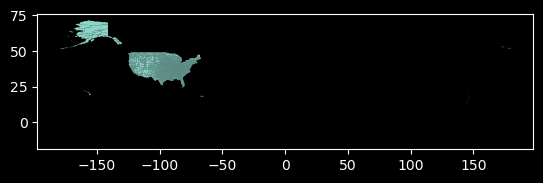

In [23]:
# d
counties.plot()

In [24]:
# Checking which states and territories are included and how many counties each contains
counties['STATEFP'].value_counts().reset_index()

,STATEFP,count
0,48,254
1,13,159
2,51,133
3,21,120
4,29,115
5,20,105
6,17,102
7,37,100
8,19,99
9,47,95


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

<Axes: >

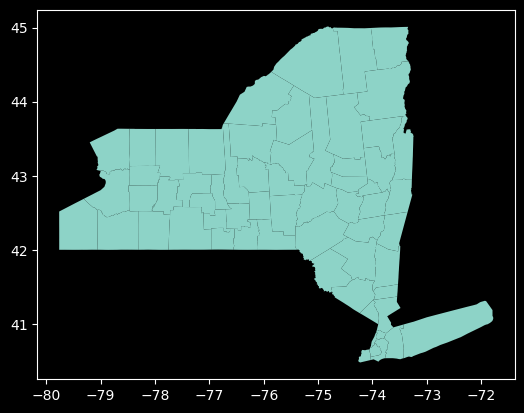

In [ ]:
# Selecting rows for counties from New York (36)
ny_counties = counties[counties['STATEFP'] == '36']

# Plotting New York counties
ny_counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [26]:
print(f"New York Counties:\n{ny_counties['NAME'].unique()}")

New York Counties:
['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [27]:
print(f"New York Counties:\n{spills_per_county['county'].unique()}")


New York Counties:
['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


In [28]:
# Checking if number of counties matches between ny_counties and spills_per_county
if (len(ny_counties['NAME'].unique()) == len(spills_per_county['county'].unique())):
    print('ny_counties and spills_per_county contain SAME number of counties')
else: 
    print(f"ny_counties and spills_per_county contain DIFFERENT number of counties: \nny_counties contains {len(ny_counties['NAME'].unique())} counties \nny_counties contains {len(spills_per_county['county'].unique())} counties")

ny_counties and spills_per_county contain DIFFERENT number of counties: 
ny_counties contains 62 counties 
ny_counties contains 66 counties


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [29]:
# Finding counties in ny_counties not in spills_per_county
diff_ny_counties = list(set(ny_counties['NAME'].unique()) - set(spills_per_county['county'].unique()))

# Finding counties in spills_per_county not in ny_counties
diff_spills_per_county = list(set(spills_per_county['county'].unique()) - set(ny_counties['NAME'].unique()))

print(f"Counties in ny_counties by not in spills_per_county: {diff_ny_counties} \nCounties in spills_per_county but not in ny_counties: {diff_spills_per_county}")

Counties in ny_counties by not in spills_per_county: ['St. Lawrence'] 
Counties in spills_per_county but not in ny_counties: ['Pennsylvania - Region 3', 'Tuscarora Indian Reservation', 'St Lawrence', 'Onondaga Indian Reservation', 'New Jersey - Region 2']


In [ ]:
# Counties in spills_per_county not in ny_counties
diff_names_spills = diff_spills_per_county
diff_names_spills


['Pennsylvania - Region 3',
 'Tuscarora Indian Reservation',
 'St Lawrence',
 'Onondaga Indian Reservation',
 'New Jersey - Region 2']

In [31]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [ ]:
# Counties in ny_counties not in spills_per_county
diff_names_ny = diff_ny_counties
diff_names_ny

['St. Lawrence']

In [33]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [ ]:
# e. Spills in each reservation
ny_reservations = spills_per_county[spills_per_county['county'].isin(['Tuscarora Indian Reservation','Onondaga Indian Reservation'])]
ny_reservations

,county,n_spills
35,Onondaga Indian Reservation,1
58,Tuscarora Indian Reservation,2


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [ ]:
# Updating 'St Lawrence' to 'St. Lawrence' in spills_per_county
spills_per_county['county'] = spills_per_county['county'].replace('St Lawrence', 'St. Lawrence')

# Checking update
assert spills_per_county['county'].str.contains('St. Lawrence').any()

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [ ]:
# a. Rename column NAME to county in ny_counties
ny_counties = ny_counties.rename(columns = {'NAME': 'county'})

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [ ]:
# Joining ny_counties with spills_per_county by county
ny_spills = ny_counties.merge(spills_per_county, how = 'inner', on = 'county')

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [ ]:
# Creating lists of counties from ny_spills and spills_per_county to check for dropped counties
ny_spills_county_list = ny_spills['county'].to_list()
spills_per_county_county_list = spills_per_county['county'].to_list() # has dropped "counties"

In [ ]:
# Creating list of "counties" that were dropped in the join
diff_county_lists = list(set(spills_per_county_county_list) - set(ny_spills_county_list))

print(f"Counties lost in join: {diff_county_lists}")

Counties lost in join: ['Pennsylvania - Region 3', 'New Jersey - Region 2', 'Tuscarora Indian Reservation', 'Onondaga Indian Reservation']


In [ ]:
# Checking number of spills in each dropped "county"
spills_per_county[spills_per_county['county'].isin(diff_county_lists)]

,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

**_Dropping these records will not effect the map, but will effect reporting information. The Tuscarora Reservation is within Niagara County, and the Onondaga Reservation is within Onondaga County. The counties do not contain the spills for the reservations and will need to be added. Additionally, New Jersey - Region 2 and 'Pennsylvania - Region 3' are included in this list. Their removal will not effect the map or any reporting information as they are not in the state of New York._**

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [ ]:
# Checking number of spills in Niagara County
print(f"Spills in Niagara County (EXCLUDING Tuscarora Indian Reservation): {ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'].to_list()}")

# Adding two spills in Tuscarora Reservation to Niagara County
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] += 2

# Checking number of spills in Niagara County and Tuscarora Reservation combined
print(f"Spills in Niagara County (INCLUDING Tuscarora Indian Reservation): {ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'].to_list()}")

Spills in Niagara County (EXCLUDING Tuscarora Indian Reservation): [97]
Spills in Niagara County (INCLUDING Tuscarora Indian Reservation): [99]


In [ ]:
# Checking number of spills in Onondaga County
print(f"Spills in Onondaga County (EXCLUDING Onondaga Indian Reservation): {ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'].to_list()}")

# Adding one spill in Onondaga Reservation to Onondaga County
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] += 1

# Checking number of spills in Onondaga County and Onondaga Reservation combined
print(f"Spills in Onondaga County (INCLUDING Onondaga Indian Reservation): {ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'].to_list()}")

Spills in Onondaga County (EXCLUDING Onondaga Indian Reservation): [214]
Spills in Onondaga County (INCLUDING Onondaga Indian Reservation): [215]


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



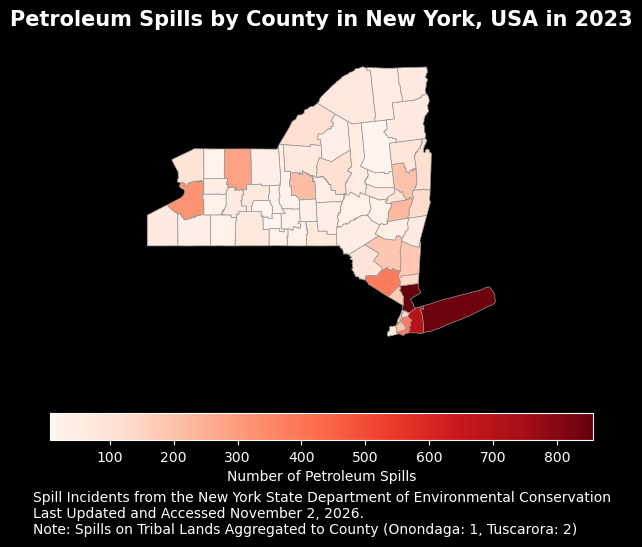

In [56]:
# Mapping petroleum spills by New York county
fig, ax = plt.subplots(figsize = (7, 5.5))
# no axes
ax.axis('off') 
# plot and legend
ny_spills.plot(ax = ax,
               column = "n_spills", 
               legend = True, 
               cmap = 'Reds', 
               edgecolor = '0.6', 
               linewidth = 0.5, 
               legend_kwds = {'label': 'Number of Petroleum Spills', 'orientation': 'horizontal'})
               # title
ax.set_title('Petroleum Spills by County in New York, USA in 2023', 
              fontsize = 15,
              fontweight = 'bold', 
              pad = 20)
# caption/annotation
fig.text(0.1, 
         0.01, 
         'Spill Incidents from the New York State Department of Environmental Conservation \nLast Updated and Accessed November 2, 2026. \nNote: Spills on Tribal Lands Aggregated to County (Onondaga: 1, Tuscarora: 2)', 
         wrap = True, 
         ha = 'left', 
         fontsize = 10)
plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

**_Description: This map of petroleum spill counts by New York county was assembled using data of spill incidents from the New York State Department of Environmental Conservation (NYSDEC) and shapefiles from the US Census Bureau. The NYSDEC spill incidents data contains information about petroleum and other hazardous materials spills, which were filtered down to spills of petroleum in 2023, and aggregated by county. Spills that occured on tribal lands were aggregated into the county that contains the reservation. A specific note was made about this choice on the figure, which includes the spill count for each reservation. Compared to spills by county on the whole, the number of spills on reservations were small and indiscernable when mapping—including this juristictional information provides transparency on how data on indigenous lands was treated. Counts of petroleum spills by county ranged from 7 to 855 with a mean of ~133 and a median of 67.5. Just a few counties around New York City in the Southeast corner of the state accounted for just shy of 30% of all petroleum spills in the state (Westchester, Suffolk, and Nassau)._**

In [ ]:
# Summary stats of spills by county
print(f"Mean Spills by County: {ny_spills['n_spills'].mean()} \nMedian Spills by County: {ny_spills['n_spills'].median()} \nMinimum Spills by County: {ny_spills['n_spills'].min()} \nMaximum Spills by County: {ny_spills['n_spills'].max()} \nTotal Spills in New York: {ny_spills['n_spills'].sum()}")

Mean Spills by County: 132.58064516129033 
Median Spills by County: 67.5 
Minimum Spills by County: 7 
Maximum Spills by County: 855 
Total Spills in New York: 8220


In [75]:
# Finding top 3 counties by number of spills and their proportion of total spills
top_3_counties = ny_spills.nlargest(3, 'n_spills')

print(f"Top 3 Counties (number of spills): {top_3_counties['county'].to_list()}")
print(f"Proportion of spills in top 3 counties: {(top_3_counties['n_spills'].sum() / ny_spills['n_spills'].sum()).round(3)}")

Top 3 Counties (number of spills): ['Westchester', 'Suffolk', 'Nassau']
Proportion of spills in top 3 counties: 0.292


## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.